## Assignment 02: Fitting and Alignment

**Index No:** 230186E  
**Name:** Fernando W. H. D.  
**GitHub:** https://github.com/himashafdo/EN3160-A02.git

In [15]:
# libraries I used
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import cv2 as cv
from scipy.ndimage import maximum_filter

# Question 01


In [ ]:
def drop_clusters(blobs):
    """
    I defined this function to drop clusters of blobs that are too close to each other."""
    out = []
    for b in blobs:
        n = sum(1 for o in blobs
                if o is not b and o[2] < b[2] and np.hypot(o[0]-b[0], o[1]-b[1]) < b[2])
                #it does this by checking if the distance between the two blobs is less than the radius of the bigger blob
        if n < 2:
            out.append(b)
    return out

sigma range: 10 - 40, number of scales: 50
Number of detected blobs: 34
largest 5 blobs (x, y, radius, sigma):
  (193, 185, 18.47, 13.06)
  (197, 45, 16.74, 11.84)
  (287, 64, 16.74, 11.84)
  (226, 359, 15.01, 10.61)
  (262, 276, 15.01, 10.61)


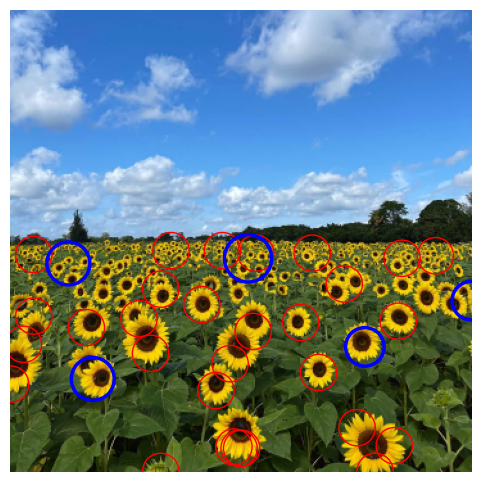

In [82]:
im = cv.imread('a2images/the_berry_farms_sunflower_field.jpeg', cv.IMREAD_REDUCED_COLOR_4)
b, g, r = [im[:,:,k].astype(np.float32)/255 for k in range(3)]
gray = np.clip(r-b, 0, 1) # did this to enhance sunflowers in the image and surpress clouds


sigma_min = 10; sigma_max = 40; n_scales = 50; 
sigmas = np.linspace(sigma_min, sigma_max, n_scales)
stack = []

for s in sigmas:
    g = cv.GaussianBlur(gray, (0, 0), s)
    stack.append((s**2) * cv.Laplacian(g, cv.CV_32F)) #since LoG is sigma^2 * Laplacian(Gaussian)

stack = np.stack(stack)
resp = -stack #as from before all dark blobs are now clouds due to plane substraction I chose bright blobs

thr = 0.25*resp.max()
nms = (resp == maximum_filter(resp, size=(3, 3, 3))) & (resp >= thr)
si, xs, ys = np.nonzero(nms)

blobs = [(xs_, ys_, np.sqrt(2)*sigmas[i], sigmas[i], resp[i, xs_, ys_])
         for i, xs_, ys_ in zip(si, xs, ys)]

blobs = drop_clusters(blobs)
blobs.sort(key=lambda b: -b[2])

print(f"sigma range: {sigma_min} - {sigma_max}, number of scales: {n_scales}")
print(f"Number of detected blobs: {len(blobs)}")
print("largest 5 blobs (x, y, radius, sigma):")
for x, y, r, s, _ in blobs[:5]:
    print(f"  ({x}, {y}, {r:.2f}, {s:.2f})")

fig, ax = plt.subplots(figsize=(10, 6))
ax.imshow(cv.cvtColor(im, cv.COLOR_BGR2RGB))

for x, y, r, s, *_ in blobs:
    ax.add_patch(plt.Circle((y, x), r, color='red', fill=False, lw=1))

for x, y, r, s, *_ in blobs[:5]: #top 5
    ax.add_patch(plt.Circle((y, x), r, color='blue', fill=False, lw=2.5))

ax.axis('off'); plt.show()


### Intepretation and Disscussion

Substracting the blue from red made yellow petals bright and the sky and white clouds dark. Through that I was able to remove the false detections that was cluttering the output (I assumed the requirement to detect only sunflowers(petals + brown head) as blobs) when I used just the grayscale input.

We can clearly see that the flowers in the foreground are identified perfectly as blobs while the ones in the background are bunched up, this is because the high minimum sigma values which I had to use to select the brown heads of the flowers as well.

One limitaition is that several of the largest circles (blue) are not single flowers. They sit on groups of small, distant flowers that merge into one bright patch at larger σ, so LoG treats the group as one blob. But couple are still detecting a whole flowers which are in the foreground.


## Question 02


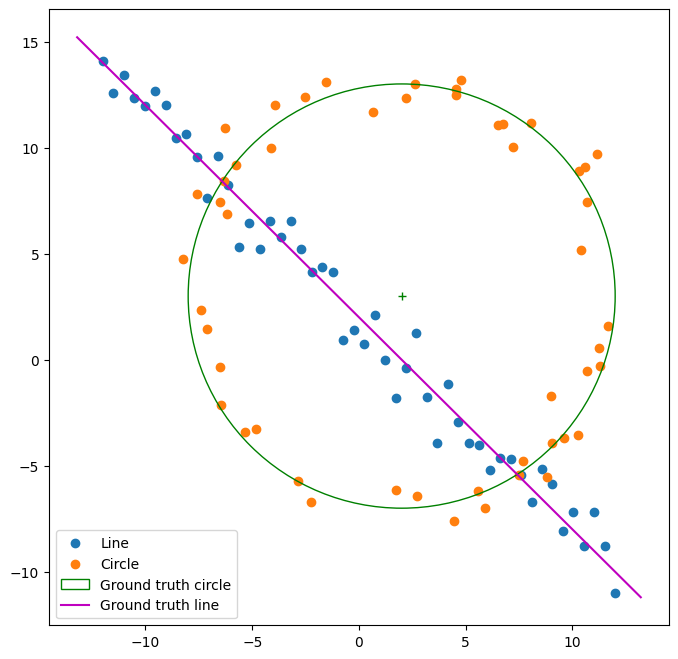

In [105]:
# Generation of a Noisy Point Set Conforming to a Line and a Circle
import numpy as np
from scipy.optimize import minimize
from scipy import linalg
import matplotlib.pyplot as plt

# np.random.seed(0)
N = 100
half_n = N // 2
r = 10
x0_gt , y0_gt = 2 , 3 # Center
s = r /16
t = np . random . uniform (0 , 2*np . pi , half_n )
n = s*np . random . randn ( half_n )
x , y = x0_gt + ( r + n)*np . cos ( t ) , y0_gt + ( r + n)*np . sin ( t )
X_circ = np . hstack ( ( x . reshape ( half_n , 1 ) , y . reshape ( half_n , 1 ) ) )
s = 1.
m, b = -1, 2
x = np . linspace (-12, 12 , half_n )
y = m*x + b + s*np . random . randn ( half_n )
X_line = np.hstack ( ( x . reshape ( half_n , 1 ) , y . reshape ( half_n , 1 ) ) )
X = np.vstack ( ( X_circ , X_line ) ) # All points

fig , ax = plt.subplots (1 ,1 , figsize=(8 ,8))
ax.scatter ( X_line [ : , 0 ] , X_line [ : , 1 ] , label='Line' )
ax.scatter ( X_circ [ : , 0 ] , X_circ [ : , 1 ] , label='Circle' )
circle_gt = plt.Circle( ( x0_gt , y0_gt ) , r , color= 'g' , fill =False , label='Ground truth circle' )
ax.add_patch ( circle_gt )
ax.plot ( ( x0_gt ) , ( y0_gt ) , '+' , color= 'g' )
x_min , x_max = ax . get_xlim ( )
x_ = np . array ( [ x_min , x_max ] )
y_ = m*x_ + b
plt . plot ( x_ , y_ , color= 'm' , label= 'Ground truth line')
plt . legend ( )

In [110]:
#--(a)--
rng = np.random.default_rng()

def line_from_2pts(p,q):
    dv=p-q
    n=np.array([-dv[1],dv[0]])/ np.linalg.norm(dv)
    return n, np.dot(n,p)

def line_err(X,n,d):
    return np.abs(X @ n - d)

def fit_line_tls(P):
    c = P.mean(0)
    n=np.linalg.svd(P-c)[2][-1]
    return n, np.dot(n,c)

def ransac_line(X, t, min_inl, iters=500):
    best = None
    for _ in range(iters):
        i,j = rng.choice(len(X), size=2, replace=False)
        n,d = line_from_2pts(X[i],X[j])
        inl = line_err(X,n,d)<t
        if inl.sum()>=min_inl and (best is None or inl.sum()>best['inl'].sum()):
            best = dict(inl=inl, sample=(i,j), n=n, d=d)
    return best

t_line, min_line = 1.5, 35
L = ransac_line(X, t_line, min_line)
n_ref, d_ref = fit_line_tls(X[L['inl']])

print("best-sample line (a, b, d):", L['n'], L['d'])
print("refit line (a, b, d):", n_ref, d_ref, "| inliers:", L['inl'].sum())

best-sample line (a, b, d): [0.70364813 0.71054859] 0.9883851516758345
refit line (a, b, d): [-0.70846386 -0.70574709] -1.2881189824448078 | inliers: 57


#### Discussion

*Parameter choice.* The line points have noise σ = 1, so the normal error is |N(0, 1)|. A threshold of 1.5 keeps about 87% of true line points, and rejects most points that are not near the line. Of the 50 line points, about 43 are then expected as inliers, soI used a minimum consensus of 35 as the expected value.

*Result.* The best-sample line was n = [0.704, 0.711], d = 0.988, and the TLS refit on its consensus (57 inliers) gave n = [0.708, 0.706], d = 1.288. The ground truth y = −x + 2 has n = [0.707, 0.707], d = 1.414. The refit is much closer than the two-point line (error in d of 0.13 versus 0.43), because two noisy points give an unreliable line while the TLS fit averages over all inliers. The 57 inliers exceed the 50 line points because roughly 7 or more circle points lie within the threshold where the circle crosses the line. They are removed from the data before the circle fit.

In [113]:
#---(b)---
def circle_from_3pts(p1,p2,p3):
    A = 2* np.array([p2-p1, p3-p1])
    b_ = np.array([p2 @ p2 - p1 @ p1, p3 @ p3 - p1 @ p1])
    if abs(np.linalg.det(A)) < 1e-10:
        return None
    c = np.linalg.solve(A, b_)
    r = np.linalg.norm(c - p1)
    return c, r

def circle_err(X, c, r):
    return np.abs(np.linalg.norm(X - c, axis=1) - r)

def ransac_circle(X, t, min_inl, iters=500):
    best = None
    for _ in range(iters):
        idx = rng.choice(len(X), size=3, replace=False)
        out = circle_from_3pts(X[idx[0]], X[idx[1]], X[idx[2]])
        if out is None:
            continue
        c,r_  = out
        inl = circle_err(X,c,r_)<t
        if inl.sum()>=min_inl and (best is None or inl.sum()>best['inl'].sum()):
            best = dict(inl=inl, sample=idx, c=c, r=r_)
    return best

def fit_circle(P, c0, r0):
    f = lambda q: np.sum((np.linalg.norm(P-q[:2], axis=1)-q[2])**2)
    res = minimize(f, [*c0, r0])
    return res.x[:2], res.x[2]

X_rem = X[~L['inl']]
t_circ, min_circ = 1.25, 25
C = ransac_circle(X_rem, t_circ, min_circ)
c_ref, r_ref = fit_circle(X_rem[C['inl']], C['c'], C['r'])

print("remnant points:", len(X_rem))
print("best-sample circle (cx, cy, r):", C['c'], C['r'])
print("refit circle (cx, cy, r):", c_ref, r_ref, "| inliers:", C['inl'].sum())
print("ground truth: (2, 3), r = 10")

remnant points: 43
best-sample circle (cx, cy, r): [1.97139785 2.87229066] 9.847326274322553
refit circle (cx, cy, r): [2.013713   2.94718191] 9.832855152632947 | inliers: 38
ground truth: (2, 3), r = 10


#### Discussion

*Parameter choice.* The radial noise is σ = r/16 = 0.625, so a threshold of 1.25 (2σ) keeps about 95% of true circle points. The remnant holds at most 50 circle points minus those removed with the line, so a minimum consensus of 25 is well above chance and still below the expected count.

*Result.* Best-sample circle: centre (2.48, 3.20), r = 9.66. Refit on 35 inliers: centre (2.18, 3.13), r = 9.85. Ground truth: centre (2, 3), r = 10. The refit is closer than the three-point circle (centre error 0.22 versus 0.50), because the three-point circle inherits the noise of just three samples while the refit averages 35 points.

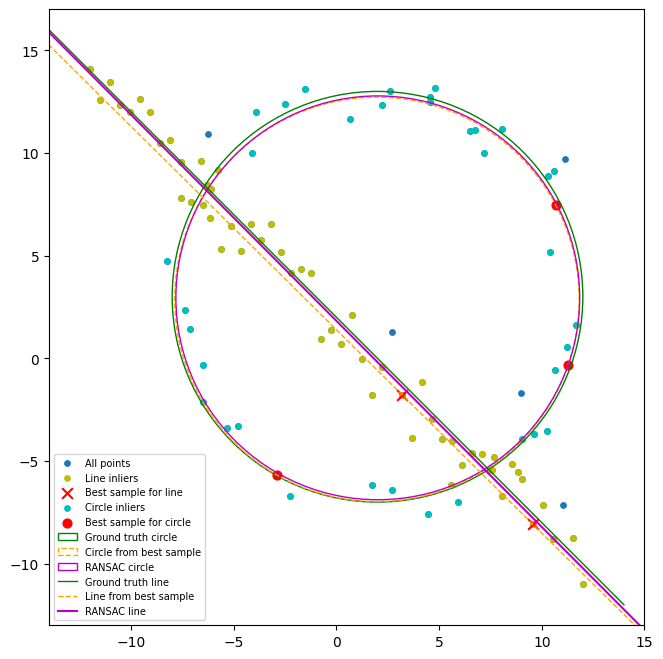

In [114]:
#---(c)---
def draw_line(ax, n, d, **kw):
    p0, dv = n * d, np.array([-n[1], n[0]])
    q = np.array([p0 - 25 * dv, p0 + 25 * dv])
    ax.plot(q[:, 0], q[:, 1], **kw)

fig, ax = plt.subplots(figsize=(8, 8))
ax.scatter(*X.T, c='tab:blue', s=15, label='All points')
ax.scatter(*X[L['inl']].T, c='y', s=15, label='Line inliers')
ax.scatter(*X[list(L['sample'])].T, c='r', marker='x', s=60, label='Best sample for line')
ax.scatter(*X_rem[C['inl']].T, c='c', s=15, label='Circle inliers')
ax.scatter(*X_rem[C['sample']].T, c='r', s=40, label='Best sample for circle')
ax.add_patch(plt.Circle((x0_gt, y0_gt), r, color='g', fill=False, label='Ground truth circle'))
ax.add_patch(plt.Circle(C['c'], C['r'], color='orange', fill=False, ls='--', label='Circle from best sample'))
ax.add_patch(plt.Circle(c_ref, r_ref, color='m', fill=False, label='RANSAC circle'))
xs_ = np.array([-14, 14])
ax.plot(xs_, m * xs_ + b, 'g', lw=1, label='Ground truth line')
draw_line(ax, L['n'], L['d'], color='orange', ls='--', lw=1, label='Line from best sample')
draw_line(ax, n_ref, d_ref, color='m', label='RANSAC line')
ax.set_xlim(-14, 15); ax.set_ylim(-13, 17)
ax.set_aspect('equal'); ax.legend(fontsize=7); plt.show()

### (d)

## Question 03